In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy import sparse
from IPython.display import display
import celloracle as co

print("Python:", sys.executable)
print("CellOracle:", co.__version__)


/home/ran3ds/.conda/envs/celloracle_env/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
which: no R in (/apps/software/standard/core/jupyterlab/4.5.6-py3.13/sbin:/apps/software/standard/core/jupyterlab/4.5.6-py3.13/bin:/opt/mam/9.1.2/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/opt/slurm/current/bin:/opt/rci/bin:/share/resources/HPCtools:/opt/mam/current/bin:/opt/apptainer/current/bin)


Python: /home/ran3ds/.conda/envs/celloracle_env/bin/python
CellOracle: 0.20.0


In [2]:
practicedata = sc.read_h5ad("Stage18_Data.h5ad")

/home/ran3ds/.conda/envs/celloracle_env/lib/python3.10/site-packages/anndata/compat/__init__.py:311: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  warn(


In [4]:
practicedata.obs["seurat_clusters"] = (
    practicedata.obs["seurat_clusters"].astype(str)
)
wt_adata = practicedata[
    (practicedata.obs["orig.ident"] == "pax6_WT") &
    (practicedata.obs["seurat_clusters"].isin(["6", "9"]))
].copy()

mutant_adata = practicedata[
    (practicedata.obs["orig.ident"] == "pax6_Mutant") &
    (practicedata.obs["seurat_clusters"].isin(["6", "9"]))
].copy()
print("WT:", wt_adata.shape)
print("Mutant:", mutant_adata.shape)

WT: (362, 22806)
Mutant: (450, 22806)


In [5]:
#this is for scaling an nonegative 
wt_adata.X = wt_adata.raw[:, wt_adata.var_names].X.copy()
mutant_adata.X = mutant_adata.raw[:, mutant_adata.var_names].X.copy()

In [7]:
base_GRN = co.data.load_xenopus_tropicalis_promoter_base_GRN(
    version="xenTro3_CisBPv2_fpr2"
)
display(base_GRN.head())


Loading prebuilt promoter base-GRN. Version: xenTro3_CisBPv2_fpr2


,peak_id,gene_short_name,AAI21521,AAI57209,AAI57537,AAI57586,AAI58894,AAI60957,AAI60967,AAI66068,...,zic4,zic5,znf143,znf238.2,znf276,znf281,znf534,znf652,znf740,zzz3
0,GL172637_1045291_1046391,izumo1r,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,GL172637_1056948_1058048,mast2,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,GL172637_1268461_1269561,pik3r3,1.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,GL172637_1717932_1719032,tspan1,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,GL172637_1786405_1787505,pomgnt1,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
# Load my gene list
genes = pd.read_csv(
    "WT_Mutant_clusters6_9_3000_genes.csv",
    header=None,
    dtype=str
)

gene_list = genes[0].str.strip().tolist()

# Keep my 3000 genes in both datasets
wt_adata = wt_adata[:, gene_list].copy()
mutant_adata = mutant_adata[:, gene_list].copy()

print("WT:", wt_adata.shape)
print("Mutant:", mutant_adata.shape)

WT: (362, 3000)
Mutant: (450, 3000)


In [11]:
# Give clusters 6 and 9 one combined label
wt_adata.obs["network_group"] = pd.Categorical(
    ["clusters6_9"] * wt_adata.n_obs
)

mutant_adata.obs["network_group"] = pd.Categorical(
    ["clusters6_9"] * mutant_adata.n_obs
)

# Keep WT and mutant as separate datasets
datasets = {
    "WT": wt_adata,
    "Mutant": mutant_adata
}

for label, adata in datasets.items():
    print(label)
    print(adata.obs["network_group"].value_counts())

WT
clusters6_9    362
Name: network_group, dtype: int64
Mutant
clusters6_9    450
Name: network_group, dtype: int64


In [12]:
# CellOracle: create Oracle objects and import the base GRN
# https://morris-lab.github.io/CellOracle.documentation/notebooks/04_Network_analysis/Network_analysis_with_Paul_etal_2015_data.html#2.-Make-Oracle-object

# Import already log-normalized, unscaled expression
# https://morris-lab.github.io/CellOracle.documentation/modules/celloracle.html#celloracle.Oracle.import_anndata_as_normalized_count

oracles = {}

for label, adata in datasets.items():

    # Create a separate Oracle object for each dataset
    oracle = co.Oracle()

    # Use combined clusters 6+9 within WT or mutant
    oracle.import_anndata_as_normalized_count(
        adata=adata,
        cluster_column_name="network_group",
        embedding_name="X_umap",
        test_mode=True
    )

    # Set the color for the combined group
    oracle.update_cluster_colors(
        palette={"clusters6_9": "#4477AA"}
    )

    # Import possible TF-to-gene connections
    oracle.import_TF_data(
        TF_info_matrix=base_GRN
    )

    # Store the WT or mutant object
    oracles[label] = oracle

    print(label, "import complete:", oracle.adata.shape)

... storing 'orig.ident' as categorical
... storing 'seurat_clusters' as categorical
... storing 'orig.ident' as categorical
... storing 'seurat_clusters' as categorical


WT import complete: (362, 3000)
Mutant import complete: (450, 3000)


In [13]:
# Perform PCA and inspect explained variance
# https://morris-lab.github.io/CellOracle.documentation/notebooks/04_Network_analysis/Network_analysis_with_Paul_etal_2015_data.html#3.-KNN-imputation

N_PCS = 20

for label, oracle in oracles.items():

    oracle.perform_PCA()

    cumulative_variance = np.cumsum(
        oracle.pca.explained_variance_ratio_
    )

    plt.figure(figsize=(5, 3))

    plt.plot(
        np.arange(1, len(cumulative_variance) + 1),
        cumulative_variance
    )

    plt.axvline(N_PCS, color="black", linestyle="--")
    plt.xlabel("Number of PCs")
    plt.ylabel("Cumulative explained variance")
    plt.title(f"{label}: combined clusters 6+9")
    plt.xlim(1, min(50, len(cumulative_variance)))
    plt.tight_layout()
    plt.show()

In [14]:
#https://morris-lab.github.io/CellOracle.documentation/notebooks/04_Network_analysis/Network_analysis_with_Paul_etal_2015_data.html#3.-KNN-imputation
#https://github.com/MinJu-Ha/CellOracle-Pipeline/blob/main/RunCellOracle.py
for label, oracle in oracles.items():

    # Count the cells in this dataset
    n_cells = oracle.adata.shape[0]

    # Use 2.5% of the cells as neighbors, as in the tutorial
    k = int(0.025 * n_cells)

    # Smooth expression using nearby cells in PCA space
    oracle.knn_imputation(
        n_pca_dims=N_PCS,
        k=k,
        balanced=True,
        b_sight=k * 8,
        b_maxl=k * 4,
        n_jobs=4
    )

    print(label, "KNN complete. Neighbors:", k)

WT KNN complete. Neighbors: 9
Mutant KNN complete. Neighbors: 11


In [15]:
#https://morris-lab.github.io/CellOracle.documentation/modules/celloracle.html#celloracle.Oracle.get_links
networks = {}

for label, oracle in oracles.items():

    networks[label] = oracle.get_links(
        cluster_name_for_GRN_unit="network_group",
        alpha=10,
        bagging_number=20,
        model_method="bagging_ridge",
        verbose_level=10,
        n_jobs=4
    )

    assert set(map(str, networks[label].links_dict)) == {"clusters6_9"}

    for group, edges in networks[label].links_dict.items():
        print(label, group, "unfiltered edges:", len(edges))


  0%|          | 0/1 [00:00<?, ?it/s]

Inferring GRN for clusters6_9...


  0%|          | 0/1365 [00:00<?, ?it/s]

WT clusters6_9 unfiltered edges: 67348


  0%|          | 0/1 [00:00<?, ?it/s]

Inferring GRN for clusters6_9...


  0%|          | 0/1365 [00:00<?, ?it/s]

Mutant clusters6_9 unfiltered edges: 67348


In [17]:
# Keep up to 4000 connections in the WT combined 6+9 network
networks["WT"].filter_links(
    p=0.001,
    weight="coef_abs",
    threshold_number=4000
)

# Keep up to 4000 connections in the mutant combined 6+9 network
networks["Mutant"].filter_links(
    p=0.001,
    weight="coef_abs",
    threshold_number=4000
)

In [18]:
print("WT: combined clusters 6+9")
display(networks["WT"].filtered_links["clusters6_9"].head(10))

print("Mutant: combined clusters 6+9")
display(networks["Mutant"].filtered_links["clusters6_9"].head(10))

WT: combined clusters 6+9


,source,target,coef_mean,coef_abs,p,-logp
22651,pax6,fgfr3,0.433255,0.433255,5.025348e-13,12.298834
22655,foxd1,fgfr3,0.410076,0.410076,4.254231e-15,14.371179
65264,rorb,vsx1,0.395486,0.395486,1.035589e-16,15.984812
22877,foxd1,flrt3,0.370021,0.370021,1.556022e-20,19.807984
1085,sox5,LOC733712,-0.324359,0.324359,2.141204e-13,12.669342
48990,rorb,rgma,-0.284895,0.284895,3.139072e-11,10.503199
1258,e2f7,LOC733945,0.271922,0.271922,2.707590e-14,13.567417
8154,e2f7,brca1,0.256414,0.256414,6.706932e-14,13.173476
20410,nr2f2,esam,-0.253789,0.253789,7.415978e-17,16.129832
65299,sox5,vsx1,-0.252528,0.252528,2.669779e-15,14.573525


Mutant: combined clusters 6+9


,source,target,coef_mean,coef_abs,p,-logp
22655,foxd1,fgfr3,0.414938,0.414938,1.216625e-19,18.914843
18999,rorb,efna5,0.353113,0.353113,1.293966e-12,11.888077
56532,rfx3,sox5,0.322869,0.322869,9.355122e-21,20.028951
19058,vax2,efnb2,-0.319042,0.319042,2.375232e-11,10.624294
65264,rorb,vsx1,0.293172,0.293172,5.340779e-15,14.272395
22657,foxn4,fgfr3,0.282152,0.282152,4.634845e-15,14.333965
19004,e2f7,efna5,-0.280899,0.280899,2.870123e-12,11.542100
31624,rorb,krt70,-0.269207,0.269207,1.370789e-11,10.863030
1276,sox5,LOC733945,-0.263911,0.263911,9.041481e-14,13.043760
41976,vax2,pax2,0.263651,0.263651,3.260518e-13,12.486713


In [19]:
# https://morris-lab.github.io/CellOracle.documentation/notebooks/04_Network_analysis/Network_analysis_with_Paul_etal_2015_data.html

for label, links in networks.items():

    if links.filtered_links["clusters6_9"].empty:
        print(label, "has no filtered connections; skipping scores.")
        continue

    # Calculate network scores
    links.get_network_score()

    scores = links.merged_score

    print(label, "combined clusters 6+9")
    print("Top genes by outgoing connections:")

    display(
        scores[scores["degree_out"] > 0]
        .nlargest(10, "degree_out")
    )

WT combined clusters 6+9
Top genes by outgoing connections:


,degree_all,degree_centrality_all,degree_in,degree_centrality_in,degree_out,degree_centrality_out,betweenness_centrality,eigenvector_centrality,cluster
vax2,199,0.271858,0,0.000000,199,0.271858,0.0,0.657604,clusters6_9
nr2f2,199,0.271858,15,0.020492,184,0.251366,8948.0,1.000000,clusters6_9
rorb,171,0.233607,0,0.000000,171,0.233607,0.0,0.821628,clusters6_9
vsx1,170,0.232240,21,0.028689,149,0.203552,6355.0,0.900351,clusters6_9
sox5,150,0.204918,11,0.015027,139,0.189891,5004.0,0.783687,clusters6_9
nr2f1,138,0.188525,7,0.009563,131,0.178962,5668.0,0.676459,clusters6_9
vax1,128,0.174863,0,0.000000,128,0.174863,0.0,0.439799,clusters6_9
lhx9,126,0.172131,0,0.000000,126,0.172131,0.0,0.421482,clusters6_9
foxp4,140,0.191257,14,0.019126,126,0.172131,6022.0,0.656262,clusters6_9
msx1,124,0.169399,9,0.012295,115,0.157104,5632.0,0.593297,clusters6_9


Mutant combined clusters 6+9
Top genes by outgoing connections:


,degree_all,degree_centrality_all,degree_in,degree_centrality_in,degree_out,degree_centrality_out,betweenness_centrality,eigenvector_centrality,cluster
vax2,227,0.315278,0,0.000000,227,0.315278,0.0,1.000000,clusters6_9
rorb,212,0.294444,0,0.000000,212,0.294444,0.0,0.977485,clusters6_9
vsx1,154,0.213889,21,0.029167,133,0.184722,7038.0,0.832782,clusters6_9
lhx9,131,0.181944,0,0.000000,131,0.181944,0.0,0.399837,clusters6_9
nr2f2,149,0.206944,20,0.027778,129,0.179167,9139.0,0.606046,clusters6_9
sox5,120,0.166667,12,0.016667,108,0.150000,6808.0,0.496530,clusters6_9
ventx2.2,107,0.148611,0,0.000000,107,0.148611,0.0,0.397784,clusters6_9
nr2f1,110,0.152778,8,0.011111,102,0.141667,5430.0,0.532133,clusters6_9
barhl1,98,0.136111,0,0.000000,98,0.136111,0.0,0.322525,clusters6_9
foxp4,113,0.156944,17,0.023611,96,0.133333,8092.0,0.542644,clusters6_9


In [20]:
# Show degree distributions for each combined network
for label, links in networks.items():

    if links.filtered_links["clusters6_9"].empty:
        print(label, "has no filtered connections; skipping plots.")
        continue

    print(label, "combined clusters 6+9")

    links.plot_degree_distributions(plot_model=True)
    plt.show()

WT combined clusters 6+9
clusters6_9
Mutant combined clusters 6+9
clusters6_9


In [21]:
# Save results for the combined cluster 6+9 networks
output_dir = Path("CellOracle_combined6_9_results")
output_dir.mkdir(parents=True, exist_ok=True)

for label, links in networks.items():

    # Save Oracle and network objects
    oracles[label].to_hdf5(
        str(output_dir / f"{label}_combined6_9.celloracle.oracle")
    )

    links.to_hdf5(
        str(output_dir / f"{label}_combined6_9.celloracle.links")
    )

    # Save unfiltered connections
    links.links_dict["clusters6_9"].to_csv(
        output_dir / f"{label}_combined6_9_unfiltered.csv",
        index=False
    )

    # Save filtered connections
    links.filtered_links["clusters6_9"].to_csv(
        output_dir / f"{label}_combined6_9_filtered.csv",
        index=False
    )

    # Save network scores if calculated
    scores = getattr(links, "merged_score", None)

    if scores is not None:
        scores.to_csv(
            output_dir / f"{label}_combined6_9_network_scores.csv"
        )

# Save the genes used
pd.DataFrame({"gene": wt_adata.var_names}).to_csv(
    output_dir / "genes_used.csv",
    index=False
)

# Save analysis settings
pd.Series({
    "python": sys.version,
    "celloracle": co.__version__,
    "scanpy": sc.__version__,
    "requested_PCs": N_PCS,
    "network_group": "clusters6_9",
    "p_cutoff": 0.001,
    "weight": "coef_abs",
    "maximum_connections": 4000
}).to_csv(
    output_dir / "analysis_settings.csv",
    header=False
)

print("Results saved in:", output_dir.resolve())

Results saved in: /sfs/gpfs/tardis/home/ran3ds/CellOracle_combined6_9_results


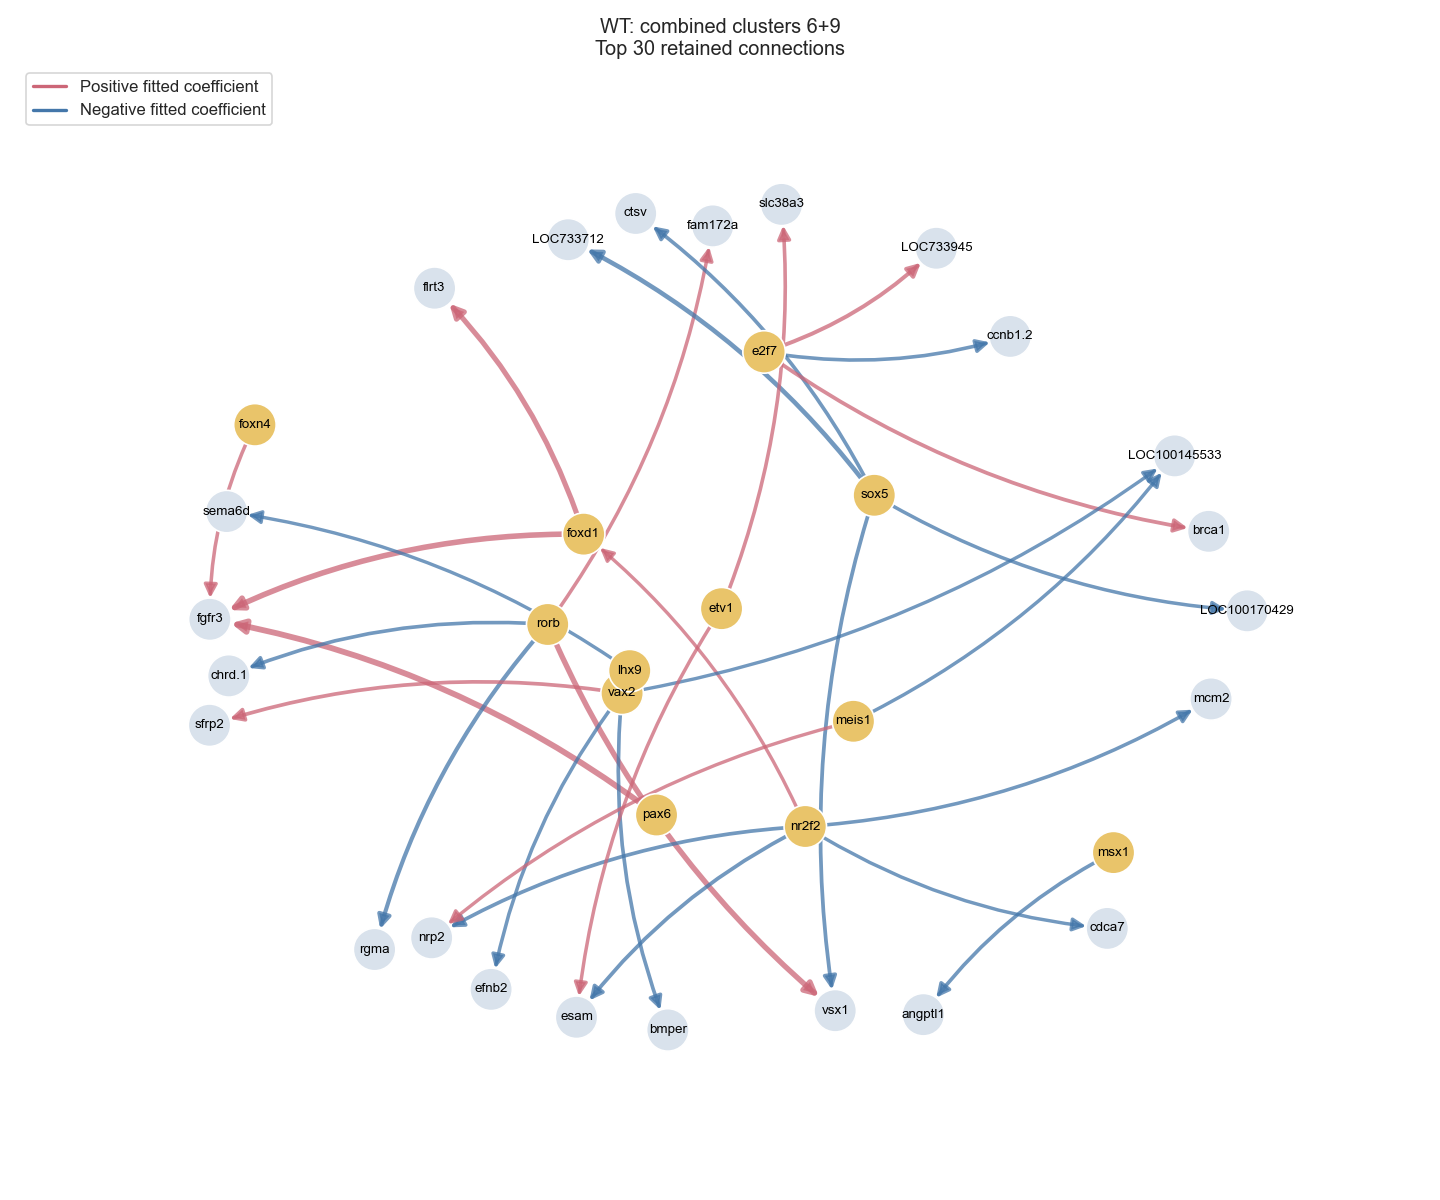

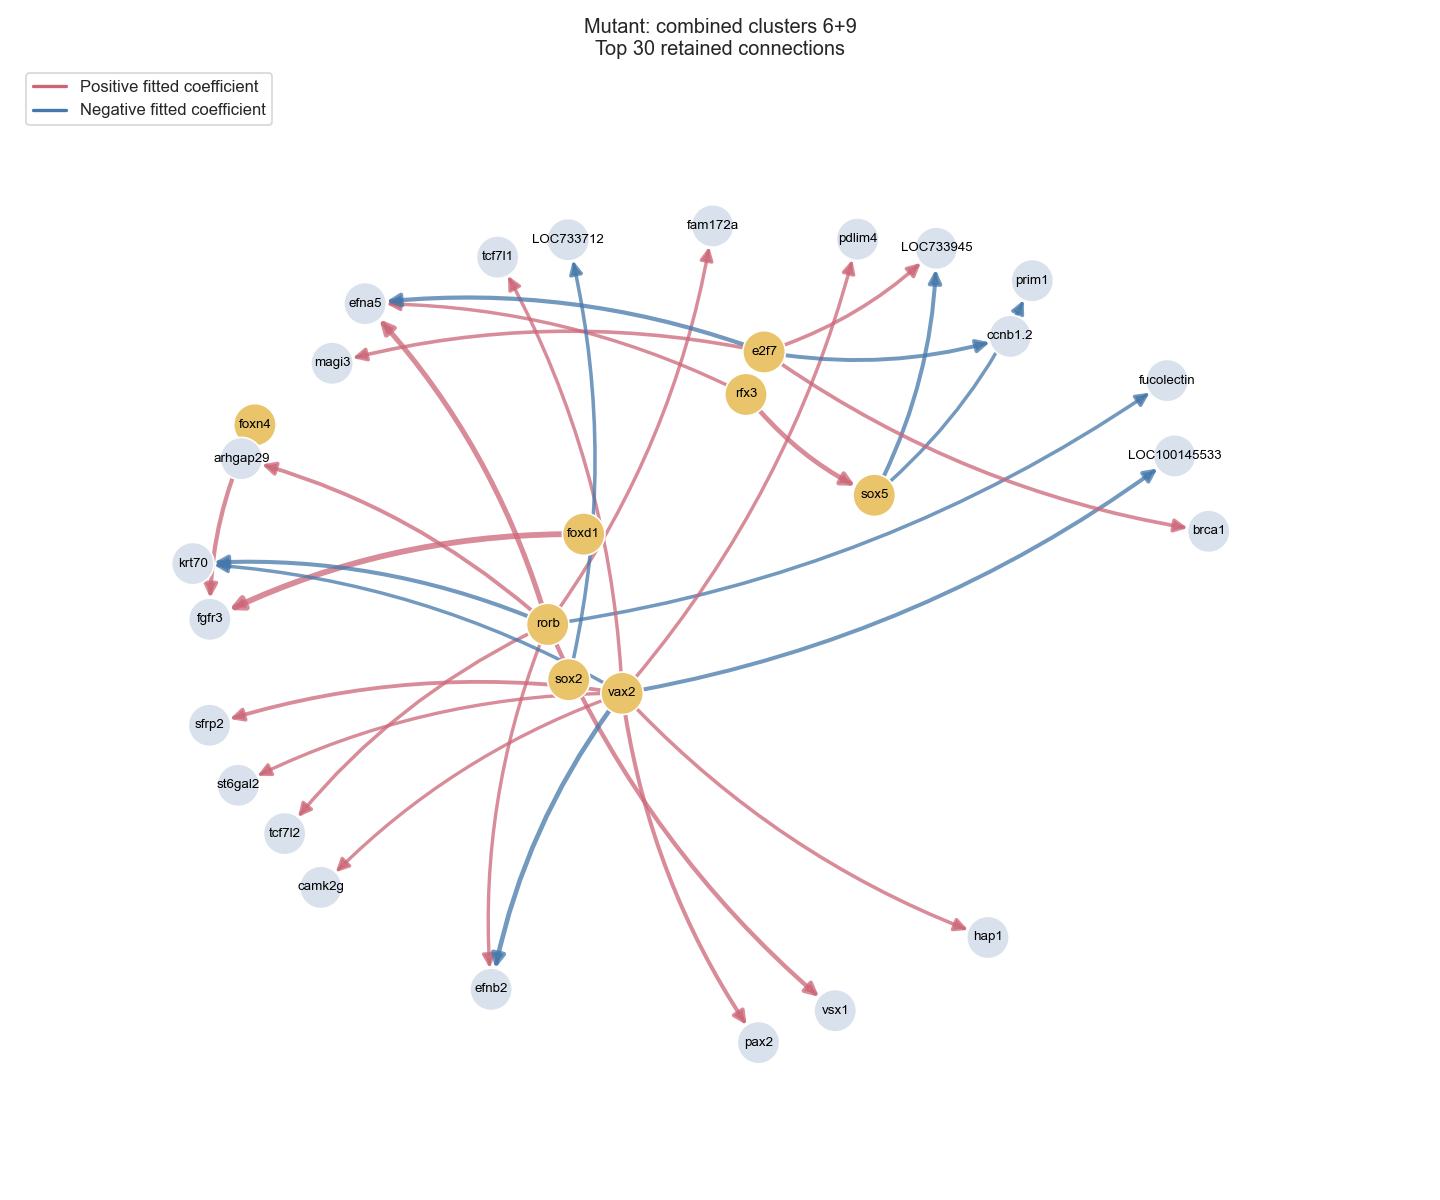

In [25]:
import networkx as nx
from io import BytesIO
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.lines import Line2D
from IPython.display import Image, display

# CellOracle stores inferred connections in filtered_links:
# https://morris-lab.github.io/CellOracle.documentation/notebooks/04_Network_analysis/Network_analysis_with_Paul_etal_2015_data.html

# Use NetworkX to draw those connections as a directed graph.
# This is a custom visualization of CellOracle results.

TOP_EDGES = 30

# Select connections for display without changing the full networks
plot_edges = {}

for label, links in networks.items():

    plot_edges[label] = (
        links.filtered_links["clusters6_9"]
        .nlargest(TOP_EDGES, "coef_abs")
        .copy()
    )

# Create shared positions so genes stay in the same place in both plots
combined_graph = nx.DiGraph()

for edges in plot_edges.values():
    combined_graph.add_edges_from(
        edges[["source", "target"]].itertuples(index=False, name=None)
    )

if combined_graph.number_of_nodes() == 0:
    raise ValueError("No filtered connections are available to plot.")

positions = nx.spring_layout(
    combined_graph,
    seed=123,
    k=1.2,
    iterations=100,
    weight=None
)

# Draw WT and mutant separately
for label, edges in plot_edges.items():

    if edges.empty:
        print(label, "has no filtered connections.")
        continue

    graph = nx.from_pandas_edgelist(
        edges,
        source="source",
        target="target",
        edge_attr=["coef_mean", "coef_abs"],
        create_using=nx.DiGraph()
    )

    edge_colors = [
        "#CC6677" if data["coef_mean"] > 0 else "#4477AA"
        for source, target, data in graph.edges(data=True)
    ]

    max_weight = edges["coef_abs"].max()

    edge_widths = [
        0.5 + 3 * data["coef_abs"] / max_weight
        if max_weight > 0 else 1
        for source, target, data in graph.edges(data=True)
    ]

    # Highlight genes with outgoing connections
    node_colors = [
        "#E9C46A" if graph.out_degree(gene) > 0 else "#D9E2EC"
        for gene in graph.nodes()
    ]

    fig = Figure(figsize=(12, 10), dpi=120)
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_subplot(111)

    nx.draw_networkx_nodes(
        graph,
        positions,
        node_color=node_colors,
        node_size=650,
        edgecolors="white",
        ax=ax
    )

    nx.draw_networkx_edges(
        graph,
        positions,
        edge_color=edge_colors,
        width=edge_widths,
        arrows=True,
        arrowsize=16,
        node_size=650,
        connectionstyle="arc3,rad=0.12",
        alpha=0.75,
        ax=ax
    )

    nx.draw_networkx_labels(
        graph,
        positions,
        font_size=8,
        ax=ax
    )

    legend = [
        Line2D([0], [0], color="#CC6677", lw=2,
               label="Positive fitted coefficient"),
        Line2D([0], [0], color="#4477AA", lw=2,
               label="Negative fitted coefficient")
    ]

    ax.legend(handles=legend, loc="upper left")
    ax.set_title(
        f"{label}: combined clusters 6+9\n"
        f"Top {len(edges)} retained connections"
    )
    ax.axis("off")

    # Keep the same coordinate limits in both diagrams
    coordinates = np.array(list(positions.values()))
    ax.set_xlim(coordinates[:, 0].min() - 0.3,
                coordinates[:, 0].max() + 0.3)
    ax.set_ylim(coordinates[:, 1].min() - 0.3,
                coordinates[:, 1].max() + 0.3)

    fig.tight_layout()

    with BytesIO() as buffer:
        canvas.print_png(buffer)
        display(Image(data=buffer.getvalue()))

    fig.clear()

In [30]:
import csv
from pathlib import Path

# Match the instruction structure in finaltemp.csv.
# BioTapestry CSV documentation:
# https://biotapestry.systemsbiology.net/tutorials/csv/CSVTutorialFullSize.html

output_folder = Path("BioTapestry_CSV")
output_folder.mkdir(parents=True, exist_ok=True)

filename = output_folder / "CellOracle_WT_Mutant_BioTapestry.csv"

P_CUTOFF = 0.001
COEF_CUTOFF = 0.1  # Chosen cutoff, not a CellOracle standard

models = {
    "WT": ("WT CellOracle Model", "wt"),
    "Mutant": ("Mutant CellOracle Model", "mt")
}

# Select connections separately for WT and mutant
selected_edges = {}

for label in models:

    # Start before the earlier 4000-edge limit
    edges = networks[label].links_dict["clusters6_9"].copy()

    edges = edges[
        (edges["p"] < P_CUTOFF)
        & (edges["coef_abs"] >= COEF_CUTOFF)
        & edges["coef_mean"].notna()
        & (edges["coef_mean"] != 0)
    ].copy()

    selected_edges[label] = (
        edges.sort_values("coef_abs", ascending=False)
        .drop_duplicates(["source", "target"])
    )

# Use the same displayed gene set in both models.
# Genes with no retained connections in a model get nodeOnly rows.
all_nodes = set()

for edges in selected_edges.values():
    all_nodes.update(edges["source"])
    all_nodes.update(edges["target"])

with open(filename, "w", newline="", encoding="utf-8") as file:

    writer = csv.writer(file, quoting=csv.QUOTE_NONNUMERIC)

    writer.writerow([
        "# Inferred coefficient signs; not experimentally proven regulation"
    ])
    writer.writerow([
        f"# Filters: p < {P_CUTOFF}; coef_abs >= {COEF_CUTOFF}"
    ])

    # Models
    writer.writerow(["# models"])
    writer.writerow(["model", "root", ""])

    for model_name, region in models.values():
        writer.writerow(["model", model_name, "root"])

    writer.writerow([])

    # Regions
    writer.writerow(["# regions"])

    for model_name, region in models.values():
        writer.writerow([
            "region",
            model_name,
            "Clusters 6 and 9",
            region
        ])

    writer.writerow([])

    # Interactions
    writer.writerow(["# interactions"])

    for label, (model_name, region) in models.items():

        edges = selected_edges[label]

        for _, edge in edges.iterrows():

            sign = (
                "positive"
                if edge["coef_mean"] > 0
                else "negative"
            )

            writer.writerow([
                "general",
                model_name,
                "gene",
                edge["source"],
                "gene",
                edge["target"],
                sign,
                region,
                region
            ])

        connected_nodes = set(edges["source"]) | set(edges["target"])

        # Show genes present in the other model even when they have
        # no connections passing these filters in this model.
        for gene in sorted(all_nodes - connected_nodes):

            writer.writerow([
                "nodeOnly",
                model_name,
                "gene",
                gene,
                region
            ])

        writer.writerow([])

# Save the numerical evidence separately
for label, edges in selected_edges.items():

    edges.to_csv(
        output_folder / f"{label}_BioTapestry_evidence.csv",
        index=False
    )

    print(label, "connections:", len(edges))
    print("Positive:", int((edges["coef_mean"] > 0).sum()))
    print("Negative:", int((edges["coef_mean"] < 0).sum()))

print("\nBioTapestry file saved:", filename.resolve())

WT connections: 529
Positive: 288
Negative: 241
Mutant connections: 453
Positive: 298
Negative: 155

BioTapestry file saved: /sfs/gpfs/tardis/home/ran3ds/BioTapestry_CSV/CellOracle_WT_Mutant_BioTapestry.csv
